In [53]:
# Grover's algorithm - toy 3-bit encryption key search
# Application: "Brute-force search" for a secret 3-bit symmetric key ( or say tja ~ tiny cipher key recovery)

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, circuit_drawer
import numpy as np
from math import pi, sqrt

# ====================== PARAMETERS ======================
n = 3                    # 3 qubits → N = 8 possible keys | 2^n so 2^3 - (2^2^2) | pw range of 0-7 : 000 -> 111
target_key = '110'       # The "secret" "correct" pw key I want to find is (6: 110)
iterations = 2           # Optimal ≈ π√N/4 = π√8/4 ≈ 2.22 → so chose to use 2, closest as we can get ( overshoot issue)
                         # N = 8: θ₀ = arcsin(1/√8)= arcsin(0.354) ≈ 20.7°
                         # Each iteration adds 2xθ₀. After k iterations, the angle is (2k+1) × θ₀ 
                         # Using 2 then = 5 x 20.7 ≈ 103.5° | Correct answer orthagonal at 90° so overshoot somewhat, but closest we can get.
                         # sin²(103.524°) ≈ 0.9453  
                         # Should then with ~94.5% | 94-95% accuracy get the correct answer after 2 grover iterations. | (I got 95%) 
print(f"Searching for secret key: {target_key} among {2**n} possibilities")

# ====================== WHY GROVER =======================
# Speedup: is significant, quadratic speedup over traditional (digital), becomes √N
#      from            O(N)       to       O(√N)
# Key length        Classical(N/2)      Grover (π/4 *√N)
# 3 bits            4 attempts          2 attempts        
# 56 bits           36 quadrillion      211 million 2^28
# 128 bits          1.7 x 10^38         1.4 x 10^19
# 256 bits          5.8 x 10^76         2.7 x 10^38
# qbits needed   | (Iterations needed, to "crack" given bit length password/encryption)
#
# Issues: for now: impractical for the size of encryption keys commonly in use (256b).  
# 256 bit - 2^256 possible keys √N giving ≈ 2^128 iterations needed
# Number of iterations - too large, stabillity/ noice also a problem.  
# Despite this some goverments have reportedly still begun gathering and saving encrypted data - 
# storing the data long term in the hopes of cracking it in the future (perhaps a bit prematurely) 
# For private individual data I would say it not very relevant or applicable yet.
# Same time for state secrets it might be worthwile, (though for now maybe better a use of resources is to monitor war thunder forums).

Searching for secret key: 110 among 8 possibilities


Oracle circuit:


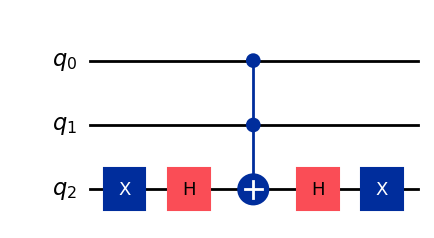

In [54]:
# ====================== STEP 2: ORACLE ======================
### The following: "target = target[::-1]" flip could sort the target issue: but I like it in. (something to yap about)
# Oracle marks the correct key with target
# Oracle: Uses X gates + H + MCX (Toffoli) + H to create a multi-controlled phase flip directly via phase kickback.
# Then entierlly witout the use of ancillas.

def create_oracle(n, target):      
    """Phase oracle that marks the target_key state.
    Uses X gates to flip 0-bits, then multi-controlled Z (via H + MCX + H)."""

    ### target = target[::-1]

    oracle = QuantumCircuit(n, name="Oracle")
    
    # Flip qubits where target has '0' so that controls see all 1s only on target
    for i, bit in enumerate(target):
        if bit == '0':
            oracle.x(i)

    # Multi-controlled Z phase flip on the target state (Toffoli)
    oracle.h(n-1)
    oracle.mcx(list(range(n-1)), n-1)   # Controlled-X on last qubit (with H becomes CZ: controlled Z)
    oracle.h(n-1)

    # Undo the X flips
    for i, bit in enumerate(target):
        if bit == '0':
            oracle.x(i)

    return oracle

oracle = create_oracle(n, target_key)
print("Oracle circuit:")
display(oracle.draw(output='mpl', style='iqp'))

Diffusion operator circuit:


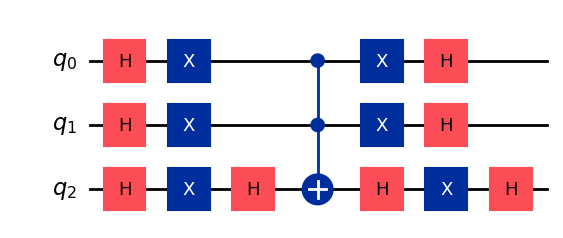

In [55]:
# ====================== STEP 3: DIFFUSION OPERATOR ======================
# Similar to oracle implementation, uses kickback implementation: no ancillas.
# then yea multicontrolled Z (through Toffoli+H)
# I was lead down that path as it was apparently the "standard textbook method for Grover when there is one marked item".
# So looking for one correct pw/key.

def diffusion(n):
    """Diffusion operator: inverts about the mean (amplifies marked state)."""
    diff = QuantumCircuit(n, name="Diffuser")

    diff.h(range(n))      # Hadamard to computational basis
    diff.x(range(n))      # X to turn |000> into |111> 
    
    # Multi-controlled Z
    diff.h(n-1)
    diff.mcx(list(range(n-1)), n-1)
    diff.h(n-1)
    
    diff.x(range(n))      # Undo X
    diff.h(range(n))      # Undo initial H

    return diff

diff = diffusion(n)
print("Diffusion operator circuit:")
display(diff.draw(output='mpl', style='iqp'))

Full Grover circuit with 2 iterations:


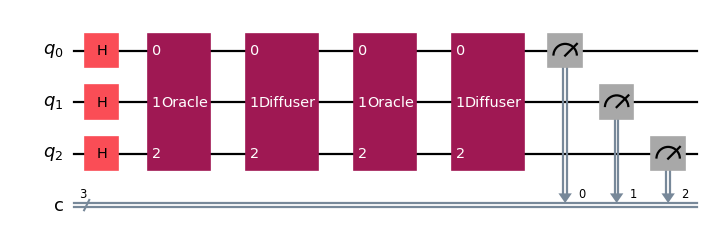

In [56]:
# ====================== STEP 4: GROVER CIRCUIT ==========================
qc = QuantumCircuit(n, n, name="Grover Key Search")

# Initialize uniform superposition with Hadamard gates 
qc.h(range(n))

# Apply the Grover iterations: oracle+diffuser (2x) | 
# So we have |0> --/n---[H]-[(Uw)-(Us)]^r---/meashurement
# r: then number of iterations : then /n same for all n (3) qbits 
for _ in range(iterations):
    qc.append(oracle.to_gate(), range(n))
    qc.append(diff.to_gate(), range(n))

# Measure all qubits
qc.measure(range(n), range(n))

print(f"Full Grover circuit with {iterations} iterations:")
display(qc.draw(output='mpl', style='iqp', scale=0.8, plot_barriers=True))

# 1 innital Hadamard gates creates superposition (puts all 8 possible keys in superposition) 1/8 prob for all answers here
# 2 

Most probable outcome: 011
Expected target key: 110


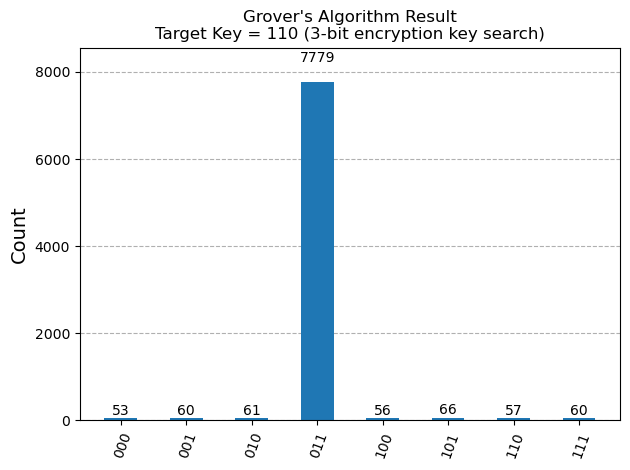

In [57]:
# ====================== STEP 5: SIMULATION / MEASHUREMENT ======================
# Did not know I needed transpile. But yea some AI assistance and I got it working with that.
from qiskit import transpile
sim = AerSimulator()

# Decompose custom Oracle and Diffuser gates into basic gates
qc_decomposed = qc.decompose()

# Transpile to match simulator's basis gates (good practice)
qc_transpiled = transpile(qc_decomposed, backend=sim, optimization_level=1)

# Run the simulation, "shots" here number of simulations: somewhat lower number perhaps even more accurate.
# each "shot" -> one meashurement result.
result = sim.run(qc_transpiled, shots=8192).result()
counts = result.get_counts()

print(f"Most probable outcome: {max(counts, key=counts.get)}")
print(f"Expected target key: {target_key}")

# Visualization, NB! Note missmatch in outcome and target key.
plot_histogram(counts, title=f"Grover's Algorithm Result\nTarget Key = {target_key} (3-bit encryption key search)")

In [58]:
# ====================== STEP 6: ANALYSIS ============================
most_frequent = max(counts, key=counts.get)
prob = counts[most_frequent] / 8192

print(f"Most probable key found: {most_frequent}")
print(f"Expected target: {target_key}")
print(f"Accuracy probability: {prob:.3f} ({prob*100:.1f}%)")
if most_frequent == target_key:
    print("Success!! The algorithm correctly found (amplified) the secret key.")
else:
    print("Incorrect, increase iterations +1 or check circuit.")

Most probable key found: 011
Expected target: 110
Accuracy probability: 0.950 (95.0%)
Incorrect, increase iterations +1 or check circuit.


In [36]:
# =================== STEP 7: INTERPRITATION ===============================
## Wrong key (oops):
# Note: Actually correct key found, but big endian / little endian. So key find 011 corresponds to the 110 key I was looking for.
# With quiskit the oracle enters the target as 0,1,1 for q0,q1,q2 rather than 1,1,0. Have fix for this, but left in on purpose.
# Had not taken this into account.(verfied works on 101 > giving 101) Just have to read the found key right to left 
# (or implement the reverse step in oracle for the target).

## Accuracy:
# Accuracy probabillity of 95% -> very close to the expected 94.5% I would say certainly within margins.  
# A reason of why it may be slightly off is the number of shoots used, 
# "simulation counts" : can be fine tuned to optimal threshhold
# Or simply down to insufficent decimal handeling in calculations

## On Iterations:
# Increasing iterations past 2; leads to LOWER acurracy (one moves past the 90° orthogonal correct answer we are seeking to match)
# See https://darshanfofadiya.com/zero-to-quantum/grovers-search
# Under here first issue 1.1 "Cracking a Secret Key" > end of 1.2.5:
# "Don't overshoot. If you keep iterating past the optimal point, the state vector rotates past 90° and the success probability drops. 
# After 3 iterations for N=8, the angle is 7 × 20.7° ≈ 145° — well past the target, and the probability drops to 33%. 
# You must stop at the right time. This is fundamentally different from classical search, where more work always helps."

## 2 Iterations: same as under paramerters | 2*3+1 = 7 (for 3 iterations)|
# Optimal ≈ π√N/4 = π√8/4 ≈ 2.22 → so chose to use 2, closest as we can get ( overshoot issue)
# N = 8: θ₀ = arcsin(1/√8)= arcsin(0.354) ≈ 20.7°
# Each iteration adds 2xθ₀. After k iterations, the angle is (2k+1) × θ₀ 
# Using 2 then = 5 x 20.7 = 103° | Correct answer at 90° so overshoot somewhat, but closest we can get.
# Should then with ~94.5% | 94-95% accuracy get the correct answer. | (after 2 grover iterations)

### Fin / thoughts: 
# Perhaps a bit overly simplified implementation / restraints chosen.
# Perhaps add even more visulaization step by step (prob distribution after H> histogram prior to mean reversal > hist/results after 1 grover iteration)
# Maybe add a toy encryption bit in the start for "immersion" ? idk.  

## Reference used as aid:
# found a very nice indepth learning guide on the very same topic: even the same example, but this used ancillas. But very good still.
# In particular for the calculation steps reused several here of his guide.
# https://darshanfofadiya.com/zero-to-quantum/grovers-search 
# @misc{fofadiya2026grovers,
#  author       = {Darshan Fofadiya},
#  title        = {Zero to Grover's Search — Zero to Quantum, Part 1},
#  year         = {2026},
#  url          = {https://darshanfofadiya.com/zero-to-quantum/grovers-search.html}

